# 04 · The hybrid multi-task network

**Indoor Location Prediction Using Wi-Fi Signals** (Project 9) · Team T084 · Phase 2

How a scan becomes the network's input columns, the network itself, and how it was tuned and
trained. The training runs are in scripts/run_dl.py (`make run2`); this notebook builds the inputs
and the network to show them, and reads every result from results/phase2/.

## 1. Input columns

**What:** fit the network's inputs (`dl.NetworkInputs`) on the cleaned training scans and transform
the test scans with them.

**Why:** a network trains well only on inputs with similar, small ranges. Everything is learned from
the training scans; the test scans are only transformed, never scaled on their own.

**Result:** 464 WAPs are heard in training and r_min = -105 dBm (1 dB below the weakest
training reading). A scan becomes 939 columns: 464 scaled RSSI values, 464 heard
indicators and 11 Phase 1 features.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from indoorloc import config, data, dl, features, plots

plt.rcParams["figure.dpi"] = 150  # larger figures in the notebook
results = config.RESULTS_DIR / "phase2"
train, _ = data.clean_training(data.load_csv(config.TRAIN_CSV))
test = data.load_csv(config.TEST_CSV)
X, y = train[config.WAP_COLS], train[config.TARGET_COLS]
inputs = dl.NetworkInputs(indicators=True, hybrid=True).fit(X, y)  # training scans only
X_test = inputs.transform(test)
n = len(inputs.waps_)
print(f"{n} WAPs heard in training, r_min = {inputs.min_rssi_:.0f} dBm")
extra = X_test.shape[1] - 2 * n
print(f"{X_test.shape[1]} columns: {n} scaled RSSI + {n} heard indicators + {extra} Phase 1 features")

464 WAPs heard in training, r_min = -105 dBm
939 columns: 464 scaled RSSI + 464 heard indicators + 11 Phase 1 features


## 2. One scan, as the network sees it

**What:** the readings of the first test scan in dBm, next to their scaled values,
(rssi - r_min) / -r_min, and their heard indicators.

**Why:** stronger readings get values closer to 1 and a WAP that is not heard gets 0; the indicator
says which WAPs are missing, so "not heard" is never mixed up with "heard very weakly".

**Result:** the scan hears 1 of the 464 kept WAPs. Its strongest reading, -91 dBm, becomes
0.133; the other 463 WAPs get 0 and indicator 0.

In [2]:
scan = test.iloc[[0]]
row = inputs.transform(scan)[0]
heard = [wap for wap in inputs.waps_ if scan[wap].iloc[0] > config.FILL_VALUE]
place = [inputs.waps_.index(wap) for wap in heard]  # column of each heard WAP
table = pd.DataFrame(
    {
        "dBm": scan[heard].iloc[0].to_numpy(),
        "scaled RSSI": row[place],
        "heard indicator": row[[n + column for column in place]],
    },
    index=heard,
)
print(f"{len(heard)} of {n} WAPs heard; every other WAP: scaled RSSI 0, indicator 0")
table.sort_values("dBm", ascending=False).head(6).round(3)

1 of 464 WAPs heard; every other WAP: scaled RSSI 0, indicator 0


,dBm,scaled RSSI,heard indicator
WAP037,-91,0.133,1.0


## 3. Scaled with training numbers only

**What:** the mean of the 11 standardized Phase 1 columns on the training scans and on the test
scans.

**Why:** the brief asks us not to normalize the test data separately: the test scans are scaled with
the training mean and standard deviation.

**Result:** every training mean is 0.00, but the test means are not (n_heard: -0.31), because
the test scans were never used to compute the scaling.

In [3]:
names = ["n_heard", "max_rssi", "mean_rssi", *features.AFFINITY_COLS]
means = {
    "training scans": inputs.transform(train)[:, -11:].mean(axis=0),
    "test scans": X_test[:, -11:].mean(axis=0),
}
pd.DataFrame(means, index=names).round(2)

,training scans,test scans
n_heard,0.0,-0.31
max_rssi,0.0,0.12
mean_rssi,-0.0,0.24
aff_b0,0.0,0.45
aff_b1,0.0,0.03
aff_b2,0.0,-0.44
aff_floor,-0.0,-0.00
aff_lon,0.0,-0.49
aff_lat,-0.0,0.47
aff_top_lon,0.0,-0.48


## 4. Hidden WAPs (regularization)

**What:** hide 10% of the heard WAPs at random (scaled RSSI and indicator set to 0), as the
network's training does in every mini-batch (`dl.hide_waps`).

**Why:** a new phone, or the same phone on another day, misses some WAPs; hiding WAPs at random
teaches the network not to depend on any single one (dropout applied to the input).

**Result:** of the 17,213 heard readings in the first 1,000 training scans, 15,472 stay heard
(10.1% hidden). Predictions never hide anything.

In [4]:
x = torch.from_numpy(inputs.transform(train.head(1000)))
rate = config.DL_FIXED["hide_wap_rate"]
hidden = dl.hide_waps(x, n, rate, torch.Generator().manual_seed(config.SEED))
before, after = int((x[:, n : 2 * n] > 0).sum()), int((hidden[:, n : 2 * n] > 0).sum())
print(f"heard readings: {before:,} before, {after:,} after hiding ({1 - after / before:.1%} hidden)")

heard readings: 17,213 before, 15,472 after hiding (10.1% hidden)


## 5. The hybrid part: Phase 1 features as inputs

**What:** the 8 AP-affinity columns of the first test scan (before standardizing), next to the true
building, floor and position.

**Why:** a WAP stays in one place, so the training scans that hear it show roughly where it is.
AP-affinity turns this into a location hint, which the hybrid network gets next to the raw readings
(the plain MLP has to learn it from the readings alone).

**Result:** the hint points to building 1 (true: 1) and a mean floor of
1.28 (true: 1); its position is 23.8 m from the true one, so
the network still has to refine it.

In [5]:
hint = inputs.affinity_.transform(scan[inputs.waps_]).iloc[0]  # learned from training scans
truth = scan[config.TARGET_COLS].iloc[0]
distance = np.hypot(hint["aff_lon"] - truth["LONGITUDE"], hint["aff_lat"] - truth["LATITUDE"])
print(f"true building {truth['BUILDINGID']}, floor {truth['FLOOR']}")
print(f"AP-affinity position: {distance:.1f} m from the true position")
hint.round(2).to_frame("first test scan")

true building 1.0, floor 1.0
AP-affinity position: 23.8 m from the true position


,first test scan
aff_b0,0.00
aff_b1,1.00
aff_b2,0.00
aff_floor,1.28
aff_lon,-7492.93
aff_lat,4864883.54
aff_top_lon,-7492.93
aff_top_lat,4864883.54


## 6. The network

**What:** the hybrid multi-task network with the tuned settings: three shared layers (the trunk)
and three heads (building, floor, position).

**Why:** one network learns all three tasks; every head reads the same 128 shared numbers, so each
task's training signal shapes the shared layers.

**Result:** 645,504 weights in the shared trunk and 1,290 in the three heads. Three separate
single-task networks would need 1,937,802 weights, about three times as many.

In [6]:
best = json.loads((results / "tuning" / "best_params.json").read_text())
params = config.DL_FIXED | best["hybrid_mlp"]  # fixed settings plus the tuned ones
tasks = ["building", "floor", "position"]
net = dl.MultiTaskMLP(X_test.shape[1], tasks, params["hidden"], params["dropout"])
print(net)
trunk = sum(p.numel() for p in net.trunk.parameters())
heads = sum(p.numel() for p in net.heads.parameters())
print(f"{trunk:,} weights in the shared trunk, {heads:,} in the three heads")

MultiTaskMLP(
  (trunk): Sequential(
    (0): Linear(in_features=939, out_features=512, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=256, out_features=128, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.2, inplace=False)
  )
  (heads): ModuleDict(
    (building): Linear(in_features=128, out_features=3, bias=True)
    (floor): Linear(in_features=128, out_features=5, bias=True)
    (position): Linear(in_features=128, out_features=2, bias=True)
  )
)
645,504 weights in the shared trunk, 1,290 in the three heads


## 7. Tuning

**What:** the user-group CV scores (mean and standard deviation over the 5 folds) of every setting
of the hybrid multi-task network (position_weight [30.0, 100.0, 300.0]), each trained for 200 epochs.

**Why:** the weight of the position loss decides how much the shared layers serve position versus
building and floor; the lowest CV mean 2D error wins (on a tie, the earlier setting).

**Result:** position_weight = 300 is chosen (9.25 m, floor accuracy 81.5%); the worst
setting reaches 9.51 m.

In [7]:
pd.read_csv(results / "tuning" / "hybrid_mlp.csv")

,position_weight,building_acc,floor_acc,mean_2d,building_acc_std,floor_acc_std,mean_2d_std,chosen
0,30.0,0.992580,0.825145,9.511539,0.012129,0.146478,2.114961,False
1,100.0,0.992805,0.799162,9.250929,0.013849,0.155026,2.133133,False
2,300.0,0.992830,0.814750,9.249904,0.008497,0.145540,2.116245,True


## 8. Learning curves

**What:** the CV mean 2D error and floor accuracy during one 200-epoch training run, scored
every 10 epochs, for the full network and for the same network without dropout and
weight decay (both from the ablation study, seed 43).

**Why:** the curves show whether the network overfits. The learning rate falls to 0 along a cosine
curve over the whole run, so the last epochs make only small changes; a point in the middle is
not what a shorter training would give.

**Result:** the tuned network goes from 9.94 m after 100 epochs to
9.21 m after 200. Without dropout and weight decay it ends at
10.28 m (its best: 10.17 m after 150 epochs).

variant,hybrid_mlp,no_regularization
epoch,,
50,11.70,10.73
100,9.94,10.43
150,9.24,10.17
200,9.21,10.28


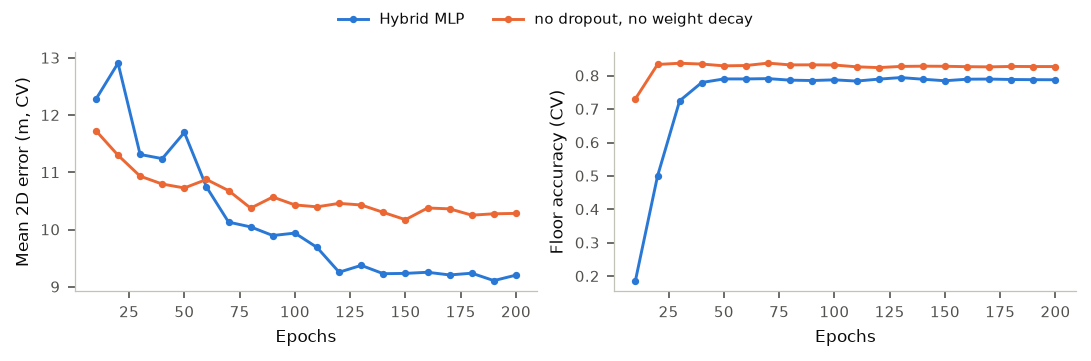

In [8]:
curves = pd.read_csv(results / "metrics" / "learning_curves.csv")
lines = {key: config.DL_VARIANTS[key]["label"] for key in config.DL_CURVES}
fig = plots.learning_curves(curves, lines)
table = curves[curves["variant"].isin(config.DL_CURVES)]
table.pivot(index="epoch", columns="variant", values="mean_2d").round(2).iloc[4::5]

## Summary

- The network gets 939 input columns per scan: scaled RSSI and heard indicators of the
  464 WAPs heard in training, and the 11 Phase 1 features (the hybrid part), all scaled with numbers
  learned from the training scans only.
- One network with 645,504 shared weights and three small heads learns building, floor and
  position together; the position-loss weight was tuned by user-group CV (position_weight = 300).
- Dropout and weight decay keep it from memorizing the training scans: after 200 epochs its
  CV error is 9.21 m, against 10.28 m
  without them (notebook 05 measures every part, including the hidden WAPs, and compares the
  network with Phase 1).